# Student Performance Analytics System

### Project Overview

This project analyzes student records stored in a MySQL database using Python.
It explores academic performance, attendance, placement status, fee collection,
and backlogs to make student information easier to understand.

### Objectives
- Analyze course-wise academic performance.
- Explore the relationship between attendance and marks.
- Summarize student placement status.
- Review fee collection and outstanding fees.
- Identify students who may need academic attention.




## 1. Import Libraries



In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")


## 2. Database Connection

In [20]:
os.chdir(r"C:\Users\Admin\OneDrive\Desktop\student management system")

from database import create_connection


connection = create_connection()

if connection:
    df = pd.read_sql("SELECT * FROM students", connection)
    print("Dataset loaded successfully!")
    print("Dataset dimensions:", df.shape)
else:
    print("Database connection failed.")



Dataset loaded successfully!
Dataset dimensions: (100, 15)


C:\Users\Admin\AppData\Local\Temp\ipykernel_10724\2179089551.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM students", connection)


## 3. Load Student Data

In [23]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nSample records:")
display(df.head(10))

print("\nNumerical summary:")
display(df.describe().T.round(2))

Dataset dimensions: (100, 15)

Column names:
['student_id', 'name', 'age', 'email', 'course', 'marks', 'gender', 'city', 'semester', 'attendance_percentage', 'enrollment_date', 'total_fees', 'fees_paid', 'backlogs', 'placement_status']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             100 non-null    int64  
 1   name                   100 non-null    str    
 2   age                    100 non-null    int64  
 3   email                  100 non-null    str    
 4   course                 100 non-null    str    
 5   marks                  100 non-null    float64
 6   gender                 100 non-null    str    
 7   city                   100 non-null    str    
 8   semester               100 non-null    int64  
 9   attendance_percentage  100 non-null    float64
 10  enrollmen

,student_id,name,age,email,course,marks,gender,city,semester,attendance_percentage,enrollment_date,total_fees,fees_paid,backlogs,placement_status
0,1,raghav,18,raghav121@gmail.com,Python,50.0,Male,Agra,1,67.0,2023-07-14,30000.0,20000.0,1,Applied
1,2,Anjali Sharma,18,anjalisharma122@gmail.com,Data Science,90.0,Female,Aligarh,2,74.0,2023-07-27,30000.0,15000.0,2,Not Started
2,3,aa,18,aa123@gmail.com,CSE,90.0,Male,Delhi,3,81.0,2023-08-09,60000.0,10000.0,3,Not Started
3,4,Rahul Sharma,19,rahulsharma124@gmail.com,Python,85.0,Female,Mathura,4,88.0,2023-08-22,30000.0,30000.0,0,Not Started
4,5,Priya Verma,20,priyaverma125@gmail.com,Data Science,92.0,Male,Agra,5,95.0,2023-09-04,30000.0,20000.0,1,Placed
5,6,Aman Singh,18,amansingh126@gmail.com,CSE,76.0,Female,Aligarh,6,61.0,2023-09-17,30000.0,15000.0,2,Applied
6,7,Neha Gupta,19,nehagupta127@gmail.com,BCA,88.0,Male,Delhi,1,68.0,2023-09-30,60000.0,10000.0,3,Not Started
7,8,Rohit Kumar,21,rohitkumar128@gmail.com,Python,67.0,Female,Mathura,2,75.0,2023-10-13,30000.0,30000.0,0,Not Started
8,9,Sneha Yadav,20,snehayadav129@gmail.com,Data Science,91.0,Male,Agra,3,82.0,2023-10-26,30000.0,20000.0,1,Not Started
9,10,Arjun Patel,19,arjunpatel130@gmail.com,CSE,73.0,Female,Aligarh,4,89.0,2023-11-08,30000.0,15000.0,2,Placed



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
student_id,100.0,50.50,29.01,1.0,25.75,50.5,75.25,100.0
age,100.0,19.81,1.34,18.0,19.00,20.0,21.00,22.0
marks,100.0,80.52,12.48,50.0,71.00,84.0,91.00,98.0
semester,100.0,3.46,1.71,1.0,2.00,3.0,5.00,6.0
attendance_percentage,100.0,79.76,11.89,60.0,69.00,80.0,90.00,100.0
total_fees,100.0,37500.00,13055.82,30000.0,30000.00,30000.0,37500.00,60000.0
fees_paid,100.0,18750.00,7432.35,10000.0,13750.00,17500.0,22500.00,30000.0
backlogs,100.0,1.50,1.12,0.0,0.75,1.5,2.25,3.0


In [ ]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_report)

## 5. Data Quality 

### Missing Values

In [ ]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_report)

## 6. Duplicate Record Checks


In [24]:
numeric_columns = [
    "age",
    "marks",
    "attendance_percentage",
    "total_fees",
    "fees_paid",
    "backlogs",
    "semester"
]

available_numeric = [
    col for col in numeric_columns if col in df.columns
]

print("Numeric column summaries:")
display(df[available_numeric].describe().T.round(2))

if "attendance_percentage" in df.columns:
    print("Attendance outside 0–100:")
    display(
        df.loc[
            (df["attendance_percentage"] < 0) |
            (df["attendance_percentage"] > 100)
        ]
    )

if "marks" in df.columns:
    print("Negative marks:")
    display(df.loc[df["marks"] < 0])

if "total_fees" in df.columns and "fees_paid" in df.columns:
    print("Negative fee values:")
    display(
        df.loc[
            (df["total_fees"] < 0) |
            (df["fees_paid"] < 0)
        ]
    )

if "placement_status" in df.columns:
    print("Placement categories:")
    display(df["placement_status"].value_counts(dropna=False))

if "course" in df.columns:
    print("Course categories:")
    display(df["course"].value_counts(dropna=False))

Numeric column summaries:


,count,mean,std,min,25%,50%,75%,max
age,100.0,19.81,1.34,18.0,19.00,20.0,21.00,22.0
marks,100.0,80.52,12.48,50.0,71.00,84.0,91.00,98.0
attendance_percentage,100.0,79.76,11.89,60.0,69.00,80.0,90.00,100.0
total_fees,100.0,37500.00,13055.82,30000.0,30000.00,30000.0,37500.00,60000.0
fees_paid,100.0,18750.00,7432.35,10000.0,13750.00,17500.0,22500.00,30000.0
backlogs,100.0,1.50,1.12,0.0,0.75,1.5,2.25,3.0
semester,100.0,3.46,1.71,1.0,2.00,3.0,5.00,6.0


Attendance outside 0–100:


,student_id,name,age,email,course,marks,gender,city,semester,attendance_percentage,enrollment_date,total_fees,fees_paid,backlogs,placement_status


Negative marks:


...

,student_id,name,age,email,course,marks,gender,city,semester,attendance_percentage,enrollment_date,total_fees,fees_paid,backlogs,placement_status


Placement categories:


placement_status
Not Started    60
Applied        20
Placed         20
Name: count, dtype: int64

Course categories:


course
Python          26
Data Science    25
CSE             25
BCA             24
Name: count, dtype: int64

In [45]:
analysis_df = df.copy()

# Remove extra spaces from text columns
text_columns = analysis_df.select_dtypes(include="object").columns

for col in text_columns:
    analysis_df[col] = analysis_df[col].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Convert selected columns to numeric values
numeric_columns = [
    "age",
    "marks",
    "attendance_percentage",
    "total_fees",
    "fees_paid",
    "backlogs",
    "semester"
]

for col in numeric_columns:
    if col in analysis_df.columns:
        analysis_df[col] = pd.to_numeric(
            analysis_df[col],
            errors="coerce"
        )

print("Working copy prepared.")
print("Original rows:", len(df))
print("Working copy rows:", len(analysis_df))

Working copy prepared.
Original rows: 100
Working copy rows: 100


C:\Users\Admin\AppData\Local\Temp\ipykernel_10724\3885705927.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = analysis_df.select_dtypes(include="object").columns


## 9. Exploratory Data Analysis



Marks summary:


,Value
count,100.000000
mean,80.520000
std,12.479867
min,50.000000
25%,71.000000
50%,84.000000
75%,91.000000
max,98.000000


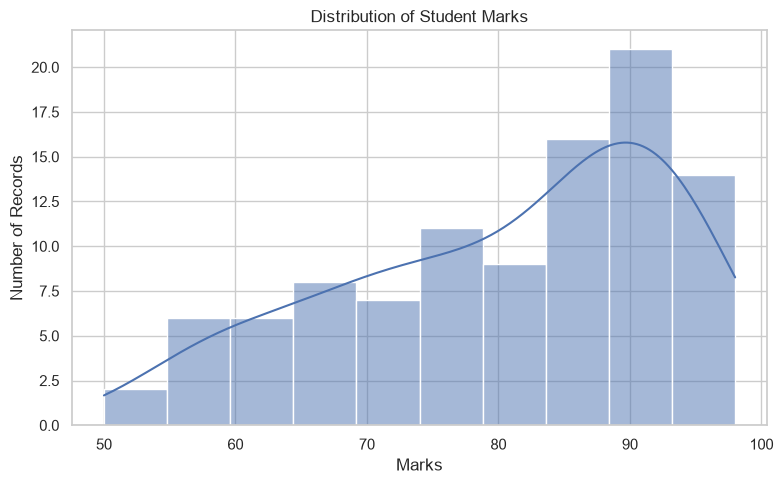

In [26]:
if "marks" in analysis_df.columns:
    marks_data = analysis_df["marks"].dropna()

    print("Marks summary:")
    display(marks_data.describe().to_frame("Value"))

    plt.figure(figsize=(8, 5))
    sns.histplot(marks_data, bins=10, kde=True)
    plt.title("Distribution of Student Marks")
    plt.xlabel("Marks")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

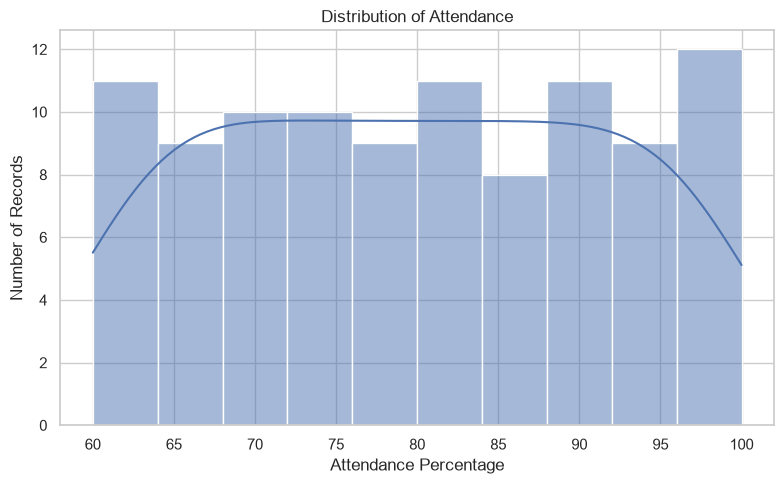

In [27]:
if "attendance_percentage" in analysis_df.columns:
    attendance_data = analysis_df["attendance_percentage"].dropna()

    plt.figure(figsize=(8, 5))
    sns.histplot(attendance_data, bins=10, kde=True)
    plt.title("Distribution of Attendance")
    plt.xlabel("Attendance Percentage")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

## 10. Course-wise Academic Performance

In [28]:
course_summary = (
    analysis_df.groupby("course", dropna=False)
    .agg(
        student_count=("student_id", "nunique"),
        average_marks=("marks", "mean"),
        average_attendance=("attendance_percentage", "mean")
    )
    .round(2)
    .sort_values("average_marks", ascending=False)
)

display(course_summary)

,student_count,average_marks,average_attendance
course,,,
Data Science,25,92.04,80.20
BCA,24,88.67,80.79
CSE,25,72.44,79.00
Python,26,69.69,79.12


In [ ]:
course_plot = course_summary.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=course_plot,
    x="course",
    y="average_marks",
    color="steelblue"
)

plt.title("Average Marks by Course")
plt.xlabel("Course")
plt.ylabel("Average Marks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 11. Attendance and Academic Performance

Attendance and marks correlation: 0.09


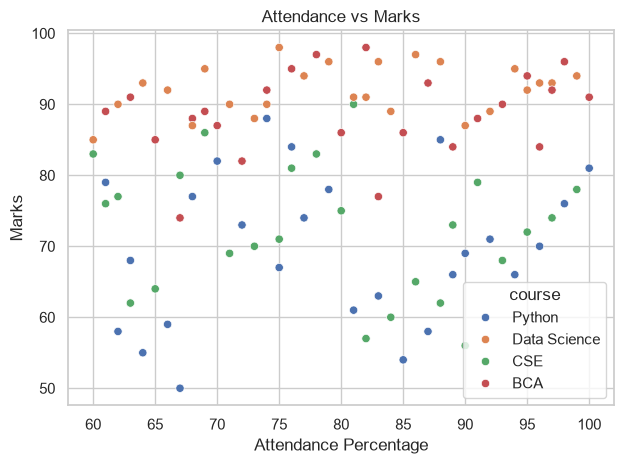

In [29]:
attendance_data = analysis_df[
    ["attendance_percentage", "marks"]
].dropna()

if len(attendance_data) >= 2:
    correlation = attendance_data["attendance_percentage"].corr(
        attendance_data["marks"]
    )

    print("Attendance and marks correlation:", round(correlation, 2))

    sns.scatterplot(
        data=analysis_df,
        x="attendance_percentage",
        y="marks",
        hue="course"
    )

    plt.title("Attendance vs Marks")
    plt.xlabel("Attendance Percentage")
    plt.ylabel("Marks")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough complete records to analyze attendance and marks.")

## 12. Placement Analysis

,Placement Status,Student Count
0,Not Started,60
1,Applied,20
2,Placed,20


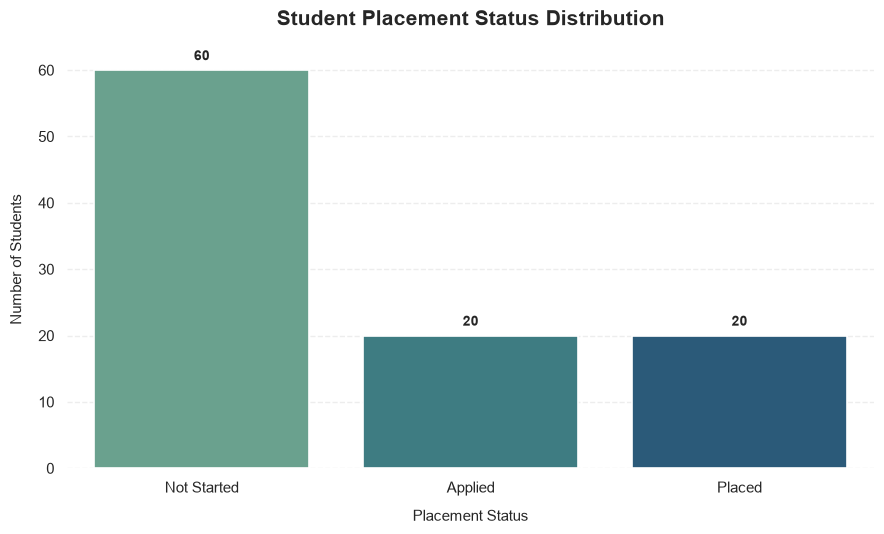

In [30]:

# Placement Status Analysis

placement_counts = (
    analysis_df["placement_status"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
    .value_counts()
    .rename_axis("Placement Status")
    .reset_index(name="Student Count")
)

display(placement_counts)

# Create a professional chart
sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.barplot(
    data=placement_counts,
    x="Placement Status",
    y="Student Count",
    hue="Placement Status",
    palette="crest",
    legend=False,
    edgecolor="white",
    linewidth=1.2,
    ax=ax
)

# Add student counts above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Student Placement Status Distribution",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Placement Status", fontsize=11, labelpad=10)
ax.set_ylabel("Number of Students", fontsize=11, labelpad=10)

ax.grid(axis="x", visible=False)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


### Fee Collection Analysis

This section analyses the fee records available in the student database. It compares total fees, fees paid, and outstanding fees to understand the overall fee collection status. Only the existing analysis data is used; the database is not modified.

In [44]:
fees_summary = pd.DataFrame({
    "Metric": [
        "Total Fees",
        "Total Fees Paid",
        "Outstanding Fees"
    ],
    "Amount": [
        analysis_df["total_fees"].sum(),
        analysis_df["fees_paid"].sum(),
        (analysis_df["total_fees"] - analysis_df["fees_paid"]).sum()
    ]
})

display(fees_summary)

,Metric,Amount
0,Total Fees,3750000.0
1,Total Fees Paid,1875000.0
2,Outstanding Fees,1875000.0


### Backlog Analysis

This section examines the distribution of student backlogs across courses. It helps identify the number of students with pending subjects and areas where additional academic support may be needed.

,course,Total_Students,Students_With_Backlogs,Average_Backlogs
1,CSE,25,25,2.04
2,Data Science,25,25,1.04
0,BCA,24,24,3.00
3,Python,26,1,0.04


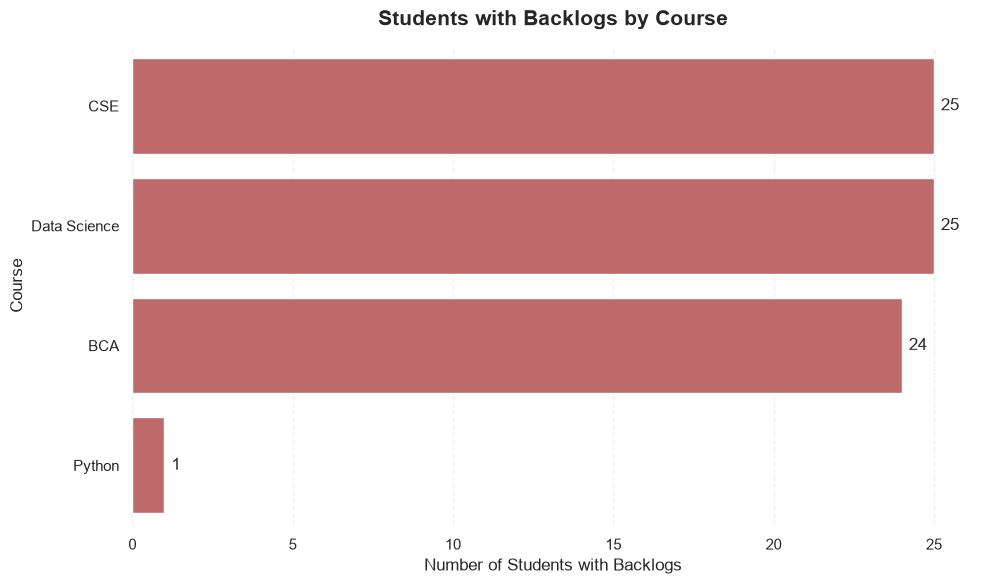

In [43]:

# Backlog Analysis by Course

backlog_data = analysis_df.dropna(
    subset=["course", "backlogs"]
).copy()

if backlog_data.empty:
    print("No valid backlog records available.")
else:
    backlog_summary = (
        backlog_data.groupby("course")
        .agg(
            Total_Students=("student_id", "nunique"),
            Students_With_Backlogs=(
                "student_id",
                lambda ids: ids[
                    backlog_data.loc[ids.index, "backlogs"] > 0
                ].nunique()
            ),
            Average_Backlogs=("backlogs", "mean")
        )
        .round(2)
        .reset_index()
    )

    backlog_summary = backlog_summary.sort_values(
        "Students_With_Backlogs",
        ascending=False
    )

    display(backlog_summary)

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.barplot(
        data=backlog_summary,
        x="Students_With_Backlogs",
        y="course",
        color="indianred",
        edgecolor="white",
        ax=ax
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=5)

    ax.set_title(
        "Students with Backlogs by Course",
        fontsize=15,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Number of Students with Backlogs")
    ax.set_ylabel("Course")
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.grid(axis="y", visible=False)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()


### Students Requiring Academic Review

This section identifies student records with attendance below 75% or one or more backlogs. The list is intended for review and support planning. The 75% attendance level is used as an analytical reference and should be checked against the institution's actual policy.

In [34]:

# Identify students who may need academic support

low_attendance = (
    analysis_df["attendance_percentage"].notna()
    & (analysis_df["attendance_percentage"] < 75)
)

has_backlogs = (
    analysis_df["backlogs"].notna()
    & (analysis_df["backlogs"] > 0)
)

attention_data = analysis_df.loc[
    low_attendance | has_backlogs
].copy()

review_columns = [
    "student_id",
    "name",
    "course",
    "marks",
    "attendance_percentage",
    "backlogs"
]

review_columns = [
    col for col in review_columns
    if col in attention_data.columns
]

attention_data = attention_data[review_columns]

print("Students flagged for review:", len(attention_data))
display(attention_data.head(20))


Students flagged for review: 84


,student_id,name,course,marks,attendance_percentage,backlogs
0,1,raghav,Python,50.0,67.0,1
1,2,Anjali Sharma,Data Science,90.0,74.0,2
2,3,aa,CSE,90.0,81.0,3
4,5,Priya Verma,Data Science,92.0,95.0,1
5,6,Aman Singh,CSE,76.0,61.0,2
6,7,Neha Gupta,BCA,88.0,68.0,3
8,9,Sneha Yadav,Data Science,91.0,82.0,1
9,10,Arjun Patel,CSE,73.0,89.0,2
10,11,Pooja Mishra,BCA,84.0,96.0,3
11,12,Vikas Chauhan,Python,58.0,62.0,0


,Reason,Student Count
0,Attendance below 75%,37
1,One or more backlogs,75


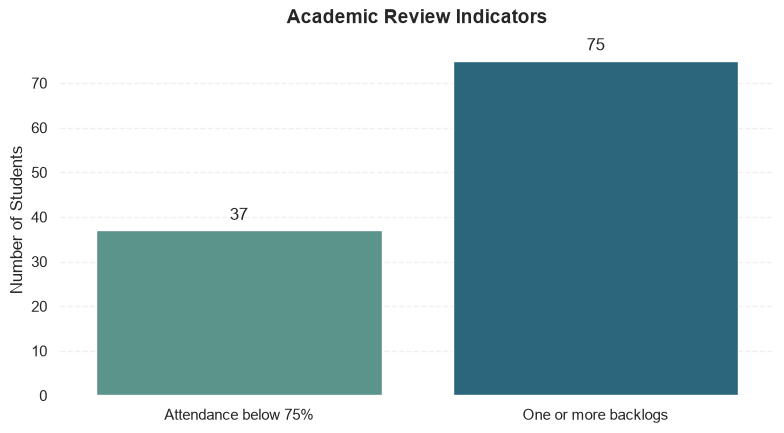

In [41]:

# Summary of academic review reasons

review_reasons = pd.DataFrame({
    "Reason": [
        "Attendance below 75%",
        "One or more backlogs"
    ],
    "Student Count": [
        int(low_attendance.sum()),
        int(has_backlogs.sum())
    ]
})

display(review_reasons)

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    data=review_reasons,
    x="Reason",
    y="Student Count",
    hue="Reason",
    palette="crest",
    legend=False,
    edgecolor="white",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5)

ax.set_title(
    "Academic Review Indicators",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("Number of Students")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


In [ ]:
analysis_df["placement_status"].value_counts(dropna=False)

### Key Performance Indicators (KPIs)

This section summarises the main academic, attendance, backlog and placement indicators in a single table. These measures provide a quick overview of the available student records.

In [40]:

# Calculate key performance indicators

total_students = analysis_df["student_id"].nunique()

average_marks = analysis_df["marks"].mean()
average_attendance = analysis_df["attendance_percentage"].mean()

students_with_backlogs = analysis_df.loc[
    analysis_df["backlogs"] > 0,
    "student_id"
].nunique()

placement_labels = (
    analysis_df["placement_status"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Check these labels against your actual database values
placed_students = placement_labels.isin(
    ["placed", "yes", "selected"]
).sum()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Unique Students",
        "Average Marks",
        "Average Attendance (%)",
        "Students with Backlogs",
        "Students Marked as Placed",
        "Students Flagged for Review"
    ],
    "Value": [
        total_students,
        round(average_marks, 2),
        round(average_attendance, 2),
        students_with_backlogs,
        int(placed_students),
        len(attention_data)
    ]
})

display(kpi_summary)


,KPI,Value
0,Total Unique Students,100.00
1,Average Marks,80.52
2,Average Attendance (%),79.76
3,Students with Backlogs,75.00
4,Students Marked as Placed,20.00
5,Students Flagged for Review,84.00


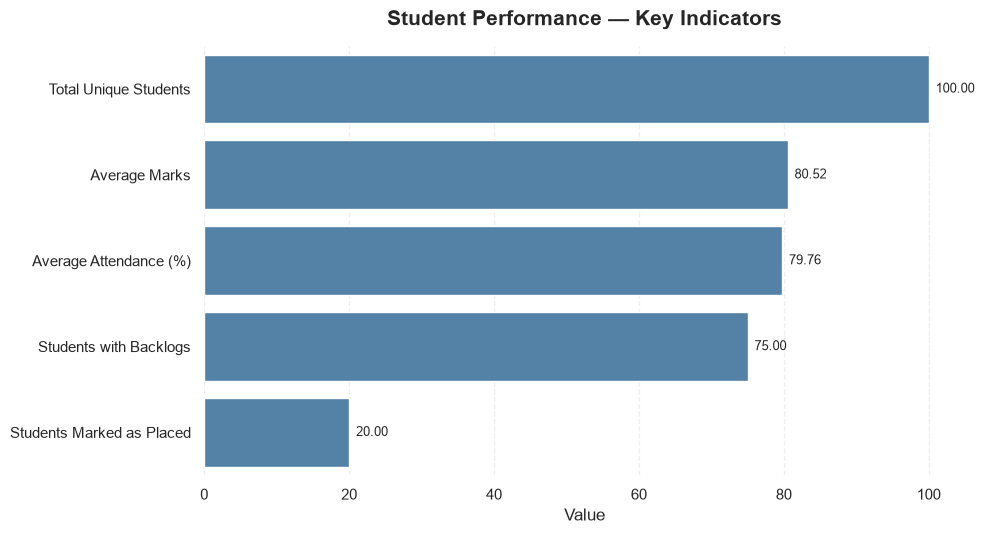

In [37]:

# Visualise key performance indicators

kpi_chart_data = kpi_summary[
    kpi_summary["KPI"].isin([
        "Total Unique Students",
        "Average Marks",
        "Average Attendance (%)",
        "Students with Backlogs",
        "Students Marked as Placed"
    ])
].copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(
    data=kpi_chart_data,
    x="Value",
    y="KPI",
    color="steelblue",
    edgecolor="white",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=5, fontsize=9)

ax.set_title(
    "Student Performance — Key Indicators",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Value")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


### Key Findings and Conclusion

The analysis examined student marks, attendance, course-wise performance, placement status, fee records and backlogs. The final findings should be based on the actual values shown in the tables and visualisations.

The results can help identify academic support needs, review fee collection records and understand placement outcomes. However, these are descriptive findings and do not establish the causes of student performance.

In [38]:

# Print a concise summary from the available data

print("STUDENT PERFORMANCE ANALYTICS")
print("=" * 38)

print(f"Total unique students: {total_students}")

if analysis_df["marks"].notna().any():
    print(f"Average marks: {average_marks:.2f}")
else:
    print("Average marks: Not available")

if analysis_df["attendance_percentage"].notna().any():
    print(f"Average attendance: {average_attendance:.2f}%")
else:
    print("Average attendance: Not available")

print(f"Students with backlogs: {students_with_backlogs}")
print(f"Students flagged for review: {len(attention_data)}")
print(f"Students marked as placed: {int(placed_students)}")

print("\nPlacement status breakdown:")
display(
    analysis_df["placement_status"]
    .value_counts(dropna=False)
    .rename_axis("Placement Status")
    .reset_index(name="Student Count")
)


STUDENT PERFORMANCE ANALYTICS
Total unique students: 100
Average marks: 80.52
Average attendance: 79.76%
Students with backlogs: 75
Students flagged for review: 84
Students marked as placed: 20

Placement status breakdown:


,Placement Status,Student Count
0,Not Started,60
1,Applied,20
2,Placed,20
